# Lab 6

You are tasked with evaluating card counting strategies for black jack. In order to do so, you will use object oriented programming to create a playable casino style black jack game where a computer dealer plays against $n$ computer players and possibly one human player. If you don't know the rules of blackjack or card counting, please google it. 

A few requirements:
* The game should utilize multiple 52-card decks. Typically the game is played with 6 decks.
* Players should have chips.
* Dealer's actions are predefined by rules of the game (typically hit on 16). 
* The players should be aware of all shown cards so that they can count cards.
* Each player could have a different strategy.
* The system should allow you to play large numbers of games, study the outcomes, and compare average winnings per hand rate for different strategies.

In [11]:
import random

class Card:
    def __init__(self, suit, rank, is_plastic=False):
        self.suit = suit
        self.rank = rank
        self.is_plastic = is_plastic 
    def __str__(self):
        if self.is_plastic:
            return
        return f"{self.rank} of {self.suit}"
        
    def __repr__(self):
        return self.__str__()

class Deck:
    def __init__(self, num_decks=1):
        self.num_decks = num_decks
        self.cards = []
        self.build()
        self.insert_plastic_card()
        self.shuffle()

    def build(self):
        suits = ['Hearts', 'Diamonds', 'Clubs', 'Spades']
        ranks = ['2', '3', '4', '5', '6', '7', '8', '9', '10', 'J', 'Q', 'K', 'A']
        
        self.cards = [Card(suit, rank) for _ in range(self.num_decks) for suit in suits for rank in ranks]

    def insert_plastic_card(self):
        plastic_card = Card(suit=None, rank=None, is_plastic=True)
        insert_index = random.randint(0, len(self.cards))
        self.cards.insert(insert_index, plastic_card)

    def shuffle(self):
        random.shuffle(self.cards)

    def draw(self):
        if len(self.cards) == 0:
            return None
        return self.cards.pop()

2. Now design your game on a UML diagram. You may want to create classes to represent, players, a hand, and/or the game. As you work through the lab, update your UML diagram. At the end of the lab, submit your diagram (as pdf file) along with your notebook. 

3. Begin with implementing the skeleton (ie define data members and methods/functions, but do not code the logic) of the classes in your UML diagram.

In [12]:
class Hand:
    def __init__(self):
        self.cards = []
        
    def add_card(self, card):
        pass
        
    def calculate_value(self):
        pass
        
    def reset(self):
        pass

class Player:
    def __init__(self, name, chips):
        self.name = name
        self.hand = Hand()
        self.chips = chips
        
    def receive_card(self, card):
        pass
        
    def place_bet(self, amount):
        pass
        
    def make_decision(self, shown_cards):
        pass
        
    def reset_hand(self):
        pass

class Dealer(Player):
    def __init__(self):
        super().__init__(name="Dealer", chips=0) 
        
    def make_decision(self, shown_cards):
        pass

class HumanPlayer(Player):
    def make_decision(self, shown_cards):
        pass

class StrategyPlayer(Player):
    def __init__(self, name, chips, threshold):
        super().__init__(name, chips)
        self.threshold = threshold
        self.current_sum = 0
        
    def make_decision(self, shown_cards):
        pass
        
    def update_count(self, visible_cards):
        pass

class Game:
    def __init__(self, num_decks=6):
        self.deck = None
        self.dealer = Dealer()
        self.players = []
        self.rounds = 0
        
    def setup_game(self):
        pass
        
    def play_round(self):
        pass
        
    def deal_initial_cards(self):
        pass
        
    def evaluate_winners(self):
        pass

4. Complete the implementation by coding the logic of all functions. For now, just implement the dealer player and human player.

In [13]:
class Hand:
    def __init__(self):
        self.cards = []
        
    def add_card(self, card):
        if card and not card.is_plastic:
            self.cards.append(card)
        
    def calculate_value(self):
        value = 0
        aces = 0
        for card in self.cards:
            if card.rank in ['J', 'Q', 'K']:
                value += 10
            elif card.rank == 'A':
                aces += 1
                value += 11
            else:
                value += int(card.rank)
                
        while value > 21 and aces > 0:
            value -= 10
            aces -= 1
            
        return value
        
    def reset(self):
        self.cards = []

class Player:
    def __init__(self, name, chips):
        self.name = name
        self.hand = Hand()
        self.chips = chips
        self.current_bet = 0
        
    def receive_card(self, card):
        self.hand.add_card(card)
        
    def place_bet(self, amount):
        if amount <= self.chips:
            self.chips -= amount
            self.current_bet = amount
            return True
        return False
        
    def make_decision(self, shown_cards):
        return "stay"
        
    def reset_hand(self):
        self.hand.reset()
        self.current_bet = 0

class Dealer(Player):
    def __init__(self):
        super().__init__(name="Dealer", chips=999999) 
        
    def make_decision(self, shown_cards=None):
        if self.hand.calculate_value() <= 16:
            return "hit"
        return "stay"

class HumanPlayer(Player):
    def make_decision(self, shown_cards):
        print(f"\n{self.name}'s Turn")
        print(f"Dealer shows: {shown_cards[0] if shown_cards else 'Unknown'}")
        print(f"Your hand: {[str(c) for c in self.hand.cards]} (Value: {self.hand.calculate_value()})")
        
        while True:
            choice = input("Do you want to (h)it or (s)tay? ").lower()
            if choice in ['h', 'hit']:
                return "hit"
            elif choice in ['s', 'stay']:
                return "stay"
            print("Invalid choice. Please enter 'h' or 's'.")

class Game:
    def __init__(self, num_decks=6):
        self.num_decks = num_decks
        self.deck = Deck(num_decks)
        self.dealer = Dealer()
        self.players = []
        self.rounds = 0
        
    def setup_game(self, players_info):
        for name, chips in players_info:
            self.players.append(HumanPlayer(name, chips))
            
    def deal_initial_cards(self):
        for _ in range(2):
            for player in self.players:
                player.receive_card(self.deck.draw())
            self.dealer.receive_card(self.deck.draw())
            
    def play_round(self):
        self.rounds += 1
        print(f"\nROUND {self.rounds}")
        
        for player in self.players:
            if player.chips >= 10:
                player.place_bet(10)
                print(f"{player.name} bets 10 chips. Remaining: {player.chips}")
            else:
                print(f"{player.name} is out of chips!")
                
        self.deal_initial_cards()
        dealer_shown = [self.dealer.hand.cards[0]]
        
        for player in self.players:
            if player.current_bet == 0:
                continue
                
            while player.hand.calculate_value() < 21:
                decision = player.make_decision(dealer_shown)
                if decision == "hit":
                    drawn_card = self.deck.draw()
                    print(f"{player.name} draws: {drawn_card}")
                    
                    if drawn_card and drawn_card.is_plastic:
                        print("Plastic card drawn! Reshuffling shoe...")
                        self.deck = Deck(self.num_decks)
                        drawn_card = self.deck.draw()
                        print(f"{player.name} draws replacement: {drawn_card}")
                        
                    player.receive_card(drawn_card)
                else:
                    print(f"{player.name} stays.")
                    break
                    
            if player.hand.calculate_value() > 21:
                print(f"{player.name} busts with {player.hand.calculate_value()}!")

        print(f"\nDealer's Turn")
        print(f"Dealer reveals: {[str(c) for c in self.dealer.hand.cards]} (Value: {self.dealer.hand.calculate_value()})")
        while self.dealer.hand.calculate_value() <= 21:
            if self.dealer.make_decision() == "hit":
                drawn_card = self.deck.draw()
                print(f"Dealer hits and draws: {drawn_card}")
                self.dealer.receive_card(drawn_card)
            else:
                print(f"Dealer stays with {self.dealer.hand.calculate_value()}.")
                break
                
        if self.dealer.hand.calculate_value() > 21:
            print("Dealer busts!")
            
        self.evaluate_winners()
        
        for player in self.players:
            player.reset_hand()
        self.dealer.reset_hand()
        
    def evaluate_winners(self):
        print("\nResults")
        dealer_val = self.dealer.hand.calculate_value()
        
        for player in self.players:
            if player.current_bet == 0:
                continue
                
            player_val = player.hand.calculate_value()
            
            if player_val > 21:
                print(f"{player.name} loses (Bust).")
            elif dealer_val > 21:
                print(f"{player.name} wins! Dealer busted.")
                player.chips += player.current_bet * 2
            elif player_val > dealer_val:
                print(f"{player.name} wins! ({player_val} to {dealer_val})")
                player.chips += player.current_bet * 2
            elif player_val == dealer_val:
                print(f"{player.name} pushes. ({player_val} tie)")
                player.chips += player.current_bet
            else:
                print(f"{player.name} loses to Dealer. ({player_val} to {dealer_val})")
                
        print(f"Current Chips: {', '.join([f'{p.name}: {p.chips}' for p in self.players])}")

5.  Test. Demonstrate game play. For example, create a game of several dealer players and show that the game is functional through several rounds.

In [14]:
test_game = Game(num_decks=6)

bot1 = Dealer()
bot1.name = "Bot 1"
bot1.chips = 100

bot2 = Dealer()
bot2.name = "Bot 2"
bot2.chips = 100

bot3 = Dealer()
bot3.name = "Bot 3"
bot3.chips = 100

test_game.players = [bot1, bot2, bot3]

print("Starting automated test with 3 Dealer-logic players...")
for i in range(3):
    test_game.play_round()

Starting automated test with 3 Dealer-logic players...

ROUND 1
Bot 1 bets 10 chips. Remaining: 90
Bot 2 bets 10 chips. Remaining: 90
Bot 3 bets 10 chips. Remaining: 90
Bot 1 draws: Q of Clubs
Bot 1 busts with 24!
Bot 2 draws: Q of Diamonds
Bot 2 stays.
Bot 3 draws: K of Spades

Dealer's Turn
Dealer reveals: ['2 of Clubs', 'J of Hearts'] (Value: 12)
Dealer hits and draws: K of Clubs
Dealer busts!

Results
Bot 1 loses (Bust).
Bot 2 wins! Dealer busted.
Bot 3 wins! Dealer busted.
Current Chips: Bot 1: 90, Bot 2: 110, Bot 3: 110

ROUND 2
Bot 1 bets 10 chips. Remaining: 80
Bot 2 bets 10 chips. Remaining: 100
Bot 3 bets 10 chips. Remaining: 100
Bot 1 stays.
Bot 2 stays.

Dealer's Turn
Dealer reveals: ['9 of Hearts', '8 of Clubs'] (Value: 17)
Dealer stays with 17.

Results
Bot 1 wins! (20 to 17)
Bot 2 wins! (18 to 17)
Bot 3 wins! (21 to 17)
Current Chips: Bot 1: 100, Bot 2: 120, Bot 3: 120

ROUND 3
Bot 1 bets 10 chips. Remaining: 90
Bot 2 bets 10 chips. Remaining: 110
Bot 3 bets 10 chips. Re

6. Implement a new player with the following strategy:

    * Assign each card a value: 
        * Cards 2 to 6 are +1 
        * Cards 7 to 9 are 0 
        * Cards 10 through Ace are -1
    * Compute the sum of the values for all cards seen so far.
    * Hit if sum is very negative, stay if sum is very positive. Select a threshold for hit/stay, e.g. 0 or -2.  

In [15]:
class StrategyPlayer(Player):
    def __init__(self, name, chips, threshold=-1):
        super().__init__(name, chips)
        self.threshold = threshold
        self.current_sum = 0
        
    def update_count(self, visible_cards):
        for card in visible_cards:
            if card and not card.is_plastic:
                if card.rank in ['2', '3', '4', '5', '6']:
                    self.current_sum += 1
                elif card.rank in ['10', 'J', 'Q', 'K', 'A']:
                    self.current_sum -= 1

    def make_decision(self, shown_cards=None):
        if shown_cards:
            self.update_count(shown_cards)

        if self.hand.calculate_value() >= 21:
            return "stay"

        if self.current_sum < self.threshold:
            return "hit"
        else:
            return "stay"

7. Create a test scenario where one player, using the above strategy, is playing with a dealer and 3 other players that follow the dealer's strategy. Each player starts with same number of chips. Play 50 rounds (or until the strategy player is out of money). Compute the strategy player's winnings. You may remove unnecessary printouts from your code (perhaps implement a verbose/quiet mode) to reduce the output.

In [16]:
class Game:
    def __init__(self, num_decks=6):
        self.num_decks = num_decks
        self.deck = Deck(num_decks)
        self.dealer = Dealer()
        self.players = []
        self.rounds = 0
        
    def setup_game(self, players_info):
        for name, chips in players_info:
            self.players.append(HumanPlayer(name, chips))

    def _draw_card_safe(self):
        drawn_card = self.deck.draw()
        if drawn_card is None or drawn_card.is_plastic:
            if drawn_card is None:
                self.deck = Deck(self.num_decks)
            else:
                pass
            self.deck = Deck(self.num_decks)
            drawn_card = self.deck.draw()
        return drawn_card
            
    def deal_initial_cards(self):
        for _ in range(2):
            for player in self.players:
                player.receive_card(self._draw_card_safe())
            self.dealer.receive_card(self._draw_card_safe())
            
    def play_round(self, verbose=True):
        self.rounds += 1
        if verbose: print(f"\nROUND {self.rounds}")
        
        for player in self.players:
            if player.chips >= 10:
                player.place_bet(10)
                if verbose: print(f"{player.name} bets 10 chips. Remaining: {player.chips}")
            else:
                if verbose: print(f"{player.name} is out of chips!")
                
        self.deal_initial_cards()
        dealer_shown = [self.dealer.hand.cards[0]]
        
        for player in self.players:
            if player.current_bet == 0:
                continue
                
            while player.hand.calculate_value() < 21:
                decision = player.make_decision(dealer_shown)
                if decision == "hit":
                    drawn_card = self._draw_card_safe()
                    if verbose: print(f"{player.name} draws: {drawn_card}")
                    player.receive_card(drawn_card)
                else:
                    if verbose: print(f"{player.name} stays.")
                    break
                    
            if player.hand.calculate_value() > 21:
                if verbose: print(f"{player.name} busts with {player.hand.calculate_value()}!")

        if verbose: print(f"\nDealer's Turn")
        if verbose: print(f"Dealer reveals: {[str(c) for c in self.dealer.hand.cards]} (Value: {self.dealer.hand.calculate_value()})")
        
        while self.dealer.hand.calculate_value() <= 21:
            if self.dealer.make_decision() == "hit":
                drawn_card = self._draw_card_safe()
                if verbose: print(f"Dealer hits and draws: {drawn_card}")
                self.dealer.receive_card(drawn_card)
            else:
                if verbose: print(f"Dealer stays with {self.dealer.hand.calculate_value()}.")
                break
                
        if self.dealer.hand.calculate_value() > 21:
            if verbose: print("Dealer busts!")
            
        self.evaluate_winners(verbose)
        
        for player in self.players:
            player.reset_hand()
        self.dealer.reset_hand()
        
    def evaluate_winners(self, verbose):
        if verbose: print("\nResults")
        dealer_val = self.dealer.hand.calculate_value()
        
        for player in self.players:
            if player.current_bet == 0:
                continue
                
            player_val = player.hand.calculate_value()
            
            if player_val > 21:
                if verbose: print(f"{player.name} loses (Bust).")
            elif dealer_val > 21:
                if verbose: print(f"{player.name} wins! Dealer busted.")
                player.chips += player.current_bet * 2
            elif player_val > dealer_val:
                if verbose: print(f"{player.name} wins! ({player_val} to {dealer_val})")
                player.chips += player.current_bet * 2
            elif player_val == dealer_val:
                if verbose: print(f"{player.name} pushes. ({player_val} tie)")
                player.chips += player.current_bet
            else:
                if verbose: print(f"{player.name} loses to Dealer. ({player_val} to {dealer_val})")
                
        if verbose: print(f"Current Chips: {', '.join([f'{p.name}: {p.chips}' for p in self.players])}")

8. Create a loop that runs 100 games of 50 rounds, as setup in previous question, and store the strategy player's chips at the end of the game (aka "winnings") in a list. Histogram the winnings. What is the average winnings per round? What is the standard deviation. What is the probability of net winning or losing after 50 rounds?


Simulating 100 games of 50 rounds... Please wait.


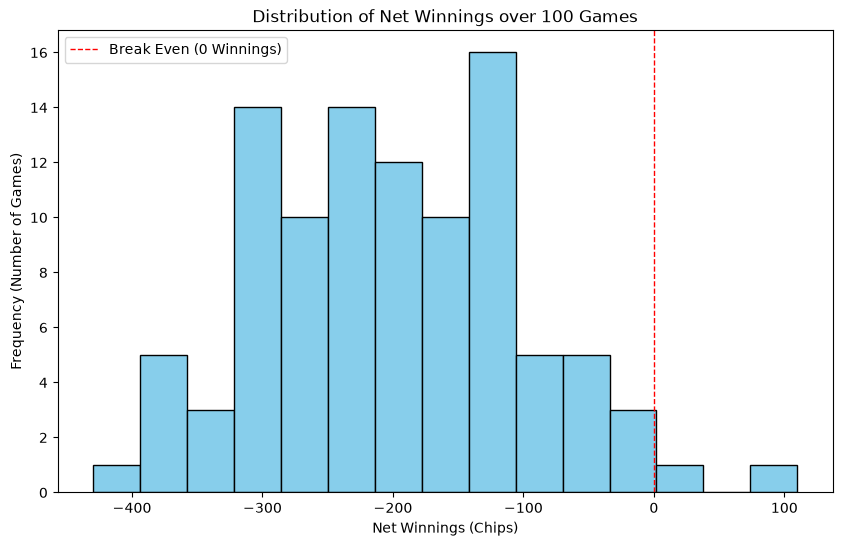

Statistics over 100 Games
Average Winnings per Game: -199.30 chips
Average Winnings per Round: -3.99 chips
Standard Deviation of Winnings: 100.74 chips
Probability of Net Winning: 2.0%
Probability of Net Losing: 97.0%
Probability of Breaking Even: 1.0%


In [17]:
import matplotlib.pyplot as plt
import numpy as np

num_games = 100
rounds_per_game = 50
initial_chips = 1000

final_chips_list = []
net_winnings_list = []

print(f"Simulating {num_games} games of {rounds_per_game} rounds... Please wait.")

for game_num in range(num_games):
    sim_game = Game(num_decks=6)
    
    strategy_p = StrategyPlayer(name="Card Counter", chips=initial_chips, threshold=0)
    bot1 = Dealer(); bot1.name = "Bot A"; bot1.chips = initial_chips
    bot2 = Dealer(); bot2.name = "Bot B"; bot2.chips = initial_chips
    bot3 = Dealer(); bot3.name = "Bot C"; bot3.chips = initial_chips
    
    sim_game.players = [strategy_p, bot1, bot2, bot3]
    
    for round_num in range(rounds_per_game):
        if strategy_p.chips < 10:
            break
            
        sim_game.play_round(verbose=False)
        
        all_visible_cards = []
        for p in sim_game.players:
            all_visible_cards.extend(p.hand.cards)
        all_visible_cards.extend(sim_game.dealer.hand.cards)
        strategy_p.update_count(all_visible_cards)

    final_chips_list.append(strategy_p.chips)
    net_winnings = strategy_p.chips - initial_chips
    net_winnings_list.append(net_winnings)


plt.figure(figsize=(10, 6))
plt.hist(net_winnings_list, bins=15, color='skyblue', edgecolor='black')
plt.title(f'Distribution of Net Winnings over {num_games} Games')
plt.xlabel('Net Winnings (Chips)')
plt.ylabel('Frequency (Number of Games)')
plt.axvline(0, color='red', linestyle='dashed', linewidth=1, label='Break Even (0 Winnings)')
plt.legend()
plt.show()

average_net_per_game = np.mean(net_winnings_list)
average_per_round = average_net_per_game / rounds_per_game
std_deviation = np.std(net_winnings_list)

wins = sum(1 for w in net_winnings_list if w > 0)
losses = sum(1 for w in net_winnings_list if w < 0)
ties = sum(1 for w in net_winnings_list if w == 0)

prob_winning = (wins / num_games) * 100
prob_losing = (losses / num_games) * 100
prob_tie = (ties / num_games) * 100

print(f"Statistics over {num_games} Games")
print(f"Average Winnings per Game: {average_net_per_game:.2f} chips")
print(f"Average Winnings per Round: {average_per_round:.2f} chips")
print(f"Standard Deviation of Winnings: {std_deviation:.2f} chips")
print(f"Probability of Net Winning: {prob_winning:.1f}%")
print(f"Probability of Net Losing: {prob_losing:.1f}%")
print(f"Probability of Breaking Even: {prob_tie:.1f}%")

9. Repeat previous questions scanning the value of the threshold. Try at least 5 different threshold values. Can you find an optimal value?

Scanning multiple threshold values...
Threshold -4 -> Average Net Winnings: -127.40
Threshold -2 -> Average Net Winnings: -141.30
Threshold  0 -> Average Net Winnings: -199.50
Threshold  2 -> Average Net Winnings: -211.50
Threshold  4 -> Average Net Winnings: -261.90

Conclusion
The optimal threshold found is -4, resulting in an average of -127.40 chips gained per 50-round game.


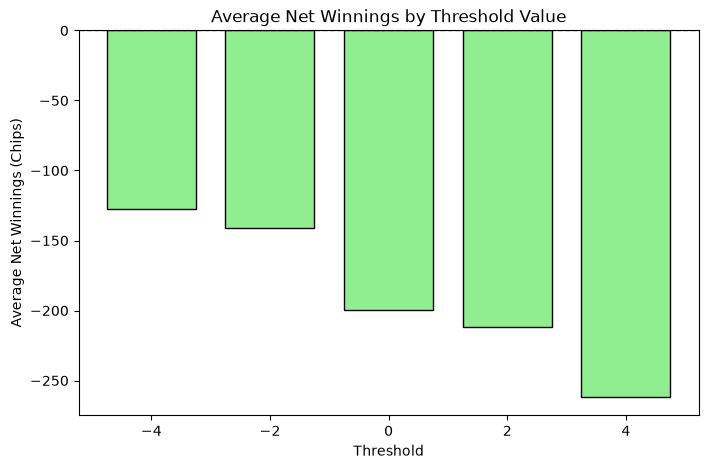

In [18]:
import matplotlib.pyplot as plt
import numpy as np

num_games = 100
rounds_per_game = 50
initial_chips = 1000

thresholds_to_test = [-4, -2, 0, 2, 4]

average_winnings_results = {}

print("Scanning multiple threshold values...")

for threshold in thresholds_to_test:
    net_winnings_list = []
    
    for game_num in range(num_games):
        sim_game = Game(num_decks=6)

        strategy_p = StrategyPlayer(name=f"Counter(Thresh={threshold})", chips=initial_chips, threshold=threshold)
        bot1 = Dealer(); bot1.name = "Bot A"; bot1.chips = initial_chips
        bot2 = Dealer(); bot2.name = "Bot B"; bot2.chips = initial_chips
        bot3 = Dealer(); bot3.name = "Bot C"; bot3.chips = initial_chips
        
        sim_game.players = [strategy_p, bot1, bot2, bot3]
        
        for round_num in range(rounds_per_game):
            if strategy_p.chips < 10:
                break
            sim_game.play_round(verbose=False)
            
            all_visible_cards = []
            for p in sim_game.players:
                all_visible_cards.extend(p.hand.cards)
            all_visible_cards.extend(sim_game.dealer.hand.cards)
            strategy_p.update_count(all_visible_cards)
            
        net_winnings = strategy_p.chips - initial_chips
        net_winnings_list.append(net_winnings)

    avg_net = np.mean(net_winnings_list)
    average_winnings_results[threshold] = avg_net
    print(f"Threshold {threshold:2d} -> Average Net Winnings: {avg_net:.2f}")

optimal_threshold = max(average_winnings_results, key=average_winnings_results.get)
max_winnings = average_winnings_results[optimal_threshold]

print(f"\nConclusion")
print(f"The optimal threshold found is {optimal_threshold}, resulting in an average of {max_winnings:.2f} chips gained per {rounds_per_game}-round game.")

plt.figure(figsize=(8, 5))
bars = plt.bar(average_winnings_results.keys(), average_winnings_results.values(), color='lightgreen', edgecolor='black', width=1.5)
plt.title("Average Net Winnings by Threshold Value")
plt.xlabel("Threshold")
plt.ylabel("Average Net Winnings (Chips)")
plt.axhline(0, color='red', linestyle='dashed', linewidth=1)
plt.xticks(thresholds_to_test)
plt.show()

10. Create a new strategy based on web searches or your own ideas. Demonstrate that the new strategy will result in increased or decreased winnings. 

In [20]:
import numpy as np
import matplotlib.pyplot as plt

class BasicStrategyPlayer(Player):
    def make_decision(self, shown_cards=None):
        my_total = self.hand.calculate_value()

        if my_total >= 21:
            return "stay"

        dealer_upcard_val = 10
        if shown_cards and len(shown_cards) > 0 and shown_cards[0] and not shown_cards[0].is_plastic:
            card = shown_cards[0]
            if card.rank in ['J', 'Q', 'K']:
                dealer_upcard_val = 10
            elif card.rank == 'A':
                dealer_upcard_val = 11
            else:
                dealer_upcard_val = int(card.rank)

        if my_total <= 11:
            return "hit"
        elif my_total == 12:
            if dealer_upcard_val in [4, 5, 6]:
                return "stay"
            else:
                return "hit"
        elif 13 <= my_total <= 16:
            if dealer_upcard_val <= 6:
                return "stay"
            else:
                return "hit"
        else: 
            return "stay"


num_games = 100
rounds_per_game = 50
initial_chips = 1000

basic_strategy_winnings = []

print("Simulating Simplified Basic Strategy...")
for game_num in range(num_games):
    sim_game = Game(num_decks=6)

    basic_p = BasicStrategyPlayer(name="Basic Strategist", chips=initial_chips)
    bot1 = Dealer(); bot1.name = "Bot A"; bot1.chips = initial_chips
    bot2 = Dealer(); bot2.name = "Bot B"; bot2.chips = initial_chips
    bot3 = Dealer(); bot3.name = "Bot C"; bot3.chips = initial_chips
    
    sim_game.players = [basic_p, bot1, bot2, bot3]
    
    for round_num in range(rounds_per_game):
        if basic_p.chips < 10:
            break 
        sim_game.play_round(verbose=False)

    basic_strategy_winnings.append(basic_p.chips - initial_chips)

avg_basic = np.mean(basic_strategy_winnings)
std_basic = np.std(basic_strategy_winnings)

print(f"\nStrategy Demonstration Results")
print(f"Strategy Used: Simplified Basic Strategy (reacting to Dealer's upcard)")
print(f"Average Net Winnings per 50-round game: {avg_basic:.2f} chips")
print(f"Standard Deviation: {std_basic:.2f} chips")

if avg_basic > 0:
    print("\nConclusion: This strategy resulted in INCREASED net positive winnings on average.")
else:
    print(f"\nConclusion: This strategy resulted in DECREASED/negative winnings on average (the house edge is tough to beat without betting variations!).")

Simulating Simplified Basic Strategy...

Strategy Demonstration Results
Strategy Used: Simplified Basic Strategy (reacting to Dealer's upcard)
Average Net Winnings per 50-round game: -43.80 chips
Standard Deviation: 67.64 chips

Conclusion: This strategy resulted in DECREASED/negative winnings on average (the house edge is tough to beat without betting variations!).
